In [37]:
#import libaries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [38]:
#Load excel  file (dataset)
df = pd.read_excel(
    "../data/ai-exposure-categories.xlsx",
    sheet_name="AI Exposure Categories",
    header=1
)

# Display the first five rows
df.head()


,2025 National Employment Matrix title,2025 National Employment Matrix code,"Employment, 2025","Employment, 2035","Employment change, numeric, 2025–35","Employment change, percent, 2025–35","Percent self-employed, 2025","Occupational openings, 2025–35, annual average","Median annual wage, dollars, 2025",Typical education needed for entry,Work experience in a related occupation,Typical on-the-job training needed to attain competency in the occupation,Relative AI exposure
0,Chief executives,11-1011,291.6,300.9,9.3,3.2,26.6,19.1,213990,Bachelor's degree,5 years or more,NaN,Very high
1,General and operations managers,11-1021,3599.0,3780.3,181.3,5.0,0.8,285.0,105770,Bachelor's degree,5 years or more,NaN,High
2,Advertising and promotions managers,11-2011,33.2,31.9,-1.2,-3.7,35.1,2.3,133660,Bachelor's degree,Less than 5 years,NaN,Very high
3,Marketing managers,11-2021,421.6,450.8,29.1,6.9,5.3,34.0,166790,Bachelor's degree,5 years or more,NaN,Very high
4,Sales managers,11-2022,650.1,679.1,29.0,4.5,0.8,47.3,148270,Bachelor's degree,Less than 5 years,NaN,High


In [39]:
#Clean the dataset

# Remove rows that do not have an occupation code
df = df.dropna(
    subset=["2025 National Employment Matrix code"]
)

# Check the number of rows and columns
print("Dataset size:", df.shape)

# Check column names
print(df.columns.tolist())

# Check for missing values
print(df.isnull().sum())


Dataset size: (831, 13)
['2025 National Employment Matrix title', '2025 National Employment Matrix code', 'Employment, 2025', 'Employment, 2035', 'Employment change, numeric, 2025–35', 'Employment change, percent, 2025–35', 'Percent self-employed, 2025', 'Occupational openings, 2025–35, annual average', 'Median annual wage, dollars, 2025', 'Typical education needed for entry', 'Work experience in a related occupation', 'Typical on-the-job training needed to attain competency in the occupation', 'Relative AI exposure']
2025 National Employment Matrix title                                          0
2025 National Employment Matrix code                                           0
Employment, 2025                                                               0
Employment, 2035                                                               0
Employment change, numeric, 2025–35                                            0
Employment change, percent, 2025–35                                    

In [40]:
#Convert the numberical columns to numeric data types

# Columns that should contain numerical values
numeric_columns = [
    "Employment, 2025",
    "Employment, 2035",
    "Employment change, percent, 2025–35",
    "Percent self-employed, 2025",
    "Occupational openings, 2025–35, annual average",
    "Median annual wage, dollars, 2025"
]

# Convert columns to numerical values
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Check the updated data types
print(df[numeric_columns].dtypes)


Employment, 2025                                  float64
Employment, 2035                                  float64
Employment change, percent, 2025–35               float64
Percent self-employed, 2025                       float64
Occupational openings, 2025–35, annual average    float64
Median annual wage, dollars, 2025                 float64
dtype: object


Relative AI exposure
Low          213
Very high    206
High         206
Moderate     206
Name: count, dtype: int64


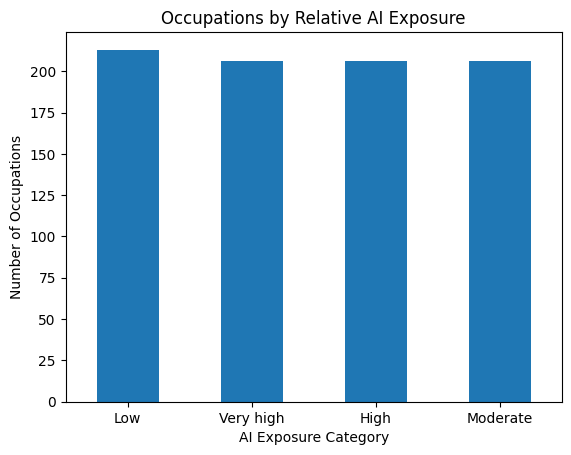

In [41]:
#Examine AI exposure categories

# Count occupations in each AI exposure category
exposure_counts = df["Relative AI exposure"].value_counts()

print(exposure_counts)

# Create a bar chart
exposure_counts.plot(kind="bar")

plt.title("Occupations by Relative AI Exposure")
plt.xlabel("AI Exposure Category")
plt.ylabel("Number of Occupations")
plt.xticks(rotation=0)
plt.savefig("../visualizations/ai_exposure_categories.png",
            dpi=300, bbox_inches="tight")
plt.show()


In [42]:
numerical_columns = [
    "Employment, 2025",
    "Employment change, percent, 2025–35",
    "Percent self-employed, 2025",
    "Occupational openings, 2025–35, annual average",
    "Median annual wage, dollars, 2025"
]

df[numerical_columns].describe()

,"Employment, 2025","Employment change, percent, 2025–35","Percent self-employed, 2025","Occupational openings, 2025–35, annual average","Median annual wage, dollars, 2025"
count,831.000000,831.000000,634.000000,831.000000,825.000000
mean,204.894344,2.077016,9.568454,21.011673,75010.848485
std,470.944336,7.240423,15.703852,61.723934,52548.781281
min,0.200000,-34.400000,0.000000,0.000000,30890.000000
25%,16.500000,-0.400000,0.900000,1.350000,47120.000000
50%,50.400000,2.700000,2.850000,4.100000,61390.000000
75%,164.000000,5.500000,9.775000,14.050000,81490.000000
max,4677.100000,41.000000,94.600000,827.400000,559030.000000


In [43]:
# Check missing values
df[numerical_columns].isnull().sum()

Employment, 2025                                    0
Employment change, percent, 2025–35                 0
Percent self-employed, 2025                       197
Occupational openings, 2025–35, annual average      0
Median annual wage, dollars, 2025                   6
dtype: int64

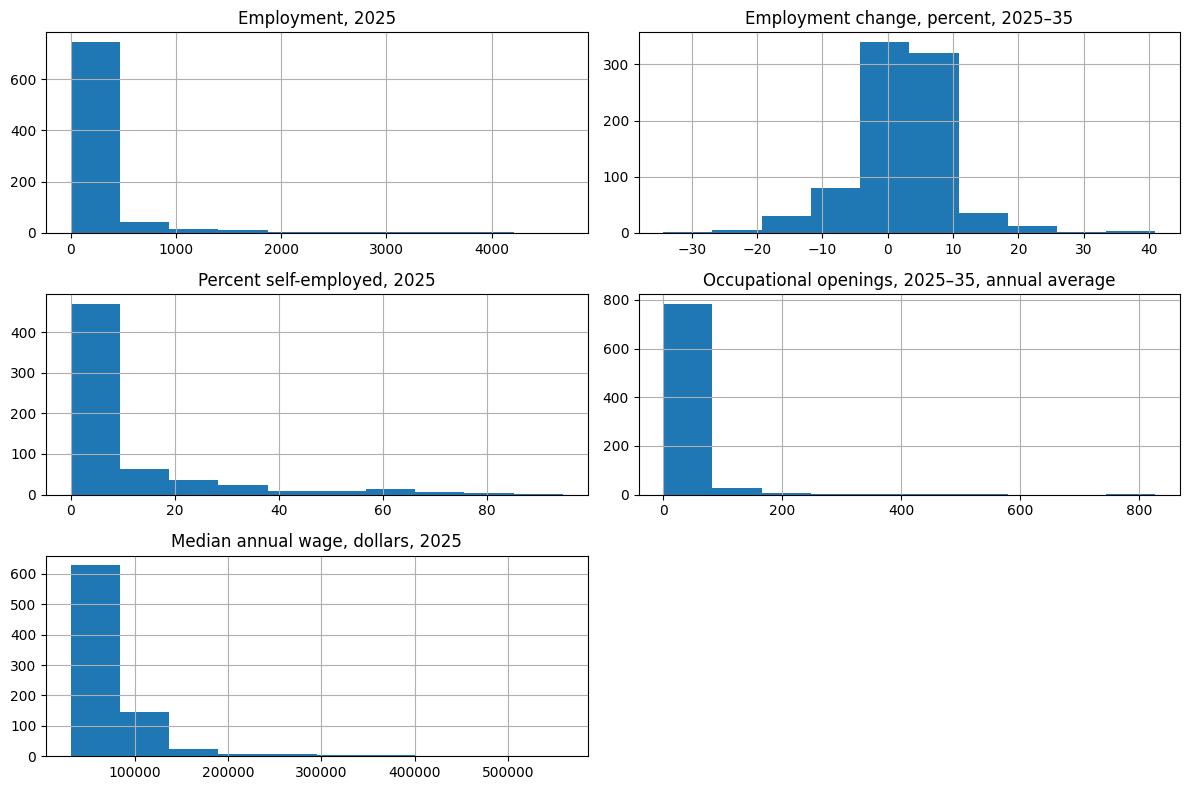

In [44]:
#create histograms before clustering
df[numerical_columns].hist(figsize=(12, 8))

plt.tight_layout()
plt.savefig("../visualizations/feature_histograms.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [45]:
#Clean and transform the data for clustering (remove any missing values and standardize the numerical columns)
import numpy as np

# Select the clustering features
features = [
    "Employment, 2025",
    "Employment change, percent, 2025–35",
    "Percent self-employed, 2025",
    "Occupational openings, 2025–35, annual average",
    "Median annual wage, dollars, 2025"
]

# Create a copy of the selected data
cluster_data = df[features].copy()

# Remove rows with missing wages
cluster_data = cluster_data.dropna(
    subset=["Median annual wage, dollars, 2025"]
)

# Replace missing self-employment values with the median
cluster_data["Percent self-employed, 2025"] = (
    cluster_data["Percent self-employed, 2025"].fillna(
        cluster_data["Percent self-employed, 2025"].median()
    )
)

# Apply log transformations
cluster_data["Employment, 2025"] = np.log1p(
    cluster_data["Employment, 2025"]
)

cluster_data["Percent self-employed, 2025"] = np.log1p(
    cluster_data["Percent self-employed, 2025"]
)

cluster_data["Occupational openings, 2025–35, annual average"] = np.log1p(
    cluster_data["Occupational openings, 2025–35, annual average"]
)

# Check the cleaned dataset
print(cluster_data.shape)
print(cluster_data.isnull().sum())

(825, 5)
Employment, 2025                                  0
Employment change, percent, 2025–35               0
Percent self-employed, 2025                       0
Occupational openings, 2025–35, annual average    0
Median annual wage, dollars, 2025                 0
dtype: int64


In [46]:
#Standardize the data
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Standardize the data
scaled_data = scaler.fit_transform(cluster_data)

# Check the standardized data
print(scaled_data.shape)
print(scaled_data[:5])

(825, 5)
[[ 1.02622931  0.15378674  1.78875417  0.80263867  2.64636885]
 [ 2.60285975  0.40180292 -0.93471182  2.77878723  0.58569979]
 [-0.32218621 -0.79694198  2.05658583 -0.54204465  1.1167667 ]
 [ 1.25715655  0.66359778  0.31503945  1.21541289  1.74761096]
 [ 1.52867452  0.33290954 -0.93471182  1.45511897  1.39496273]]


In [47]:
#Test different numbers of clusters (k) and evaluate the clustering performance using inertia and silhouette scores
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia_values = []
silhouette_values = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(scaled_data)

    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(silhouette_score(scaled_data, labels))

print("Inertia:", inertia_values)
print("Silhouette scores:", silhouette_values)

Inertia: [2933.9889346487694, 2423.8999482535005, 2024.6277910864565, 1723.889608640669, 1508.089332800785, 1350.5031878983978, 1211.5798607803545, 1142.5819388325142, 1076.9388966949346]
Silhouette scores: [np.float64(0.28334632404807114), np.float64(0.30702041270448605), np.float64(0.2859394025608447), np.float64(0.2829836638024867), np.float64(0.2601196331864997), np.float64(0.27051184917402726), np.float64(0.27443247371739227), np.float64(0.27180068256454976), np.float64(0.2328046111446622)]


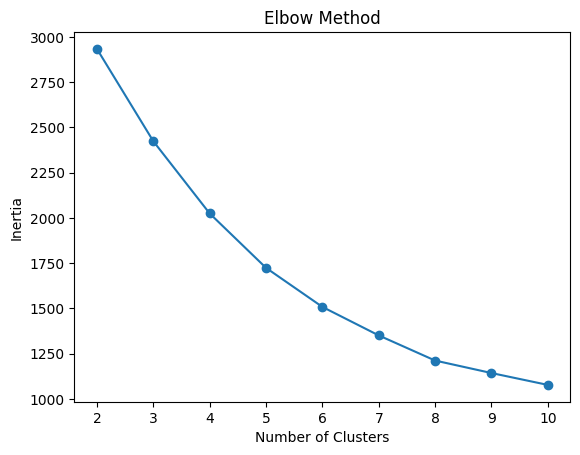

In [48]:
#Elbow chart
plt.plot(range(2, 11), inertia_values, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.savefig("../visualizations/elbow_method.png",
            dpi=300, bbox_inches="tight")
plt.show()

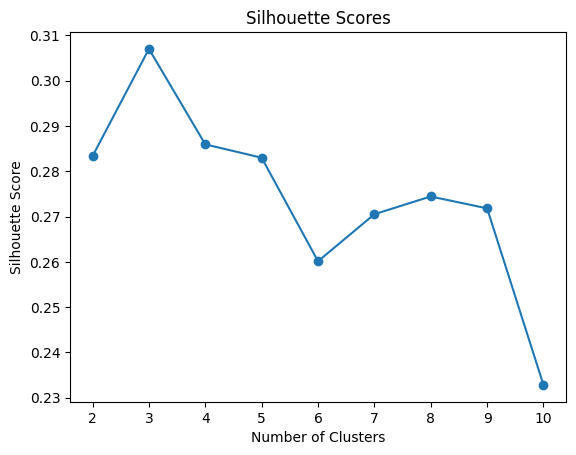

In [49]:
#Silhouette chart
plt.plot(range(2, 11), silhouette_values, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Scores")
plt.savefig("../visualizations/silhouette_scores.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [50]:
# Create K-means model
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Assign cluster labels
cluster_labels = kmeans.fit_predict(scaled_data)

# Add cluster labels to cleaned dataset
cluster_data["Cluster"] = cluster_labels

# Check number of occupations in each cluster
print(
    cluster_data["Cluster"].value_counts().sort_index()
)

Cluster
0     25
1    476
2    324
Name: count, dtype: int64


In [51]:
#Examime cluster characteristics
cluster_summary = cluster_data.groupby("Cluster").mean()

print(cluster_summary)

         Employment, 2025  Employment change, percent, 2025–35  \
Cluster                                                          
0                3.143220                             4.600000   
1                3.028620                             0.232983   
2                5.608096                             4.608951   

         Percent self-employed, 2025  \
Cluster                                
0                           1.910734   
1                           1.712890   
2                           1.218567   

         Occupational openings, 2025–35, annual average  \
Cluster                                                   
0                                              0.727469   
1                                              1.063827   
2                                              3.275570   

         Median annual wage, dollars, 2025  
Cluster                                     
0                            310838.400000  
1                             68319.8

In [52]:
#Identify occcupations in each cluster
cluster_0 = df.loc[
    cluster_data.index[cluster_data["Cluster"] == 0]
]

print(
    cluster_0[
        [
            "2025 National Employment Matrix title",
            "Median annual wage, dollars, 2025"
        ]
    ].sort_values(
        by="Median annual wage, dollars, 2025",
        ascending=False
    ).to_string(index=False)
)

         2025 National Employment Matrix title  Median annual wage, dollars, 2025
                            Pediatric surgeons                           559030.0
                                 Cardiologists                           496010.0
                                  Radiologists                           420860.0
                           Surgeons, all other                           414010.0
                             Anesthesiologists                           391490.0
         Orthopedic surgeons, except pediatric                           358550.0
               Oral and maxillofacial surgeons                           352220.0
                 Emergency medicine physicians                           335550.0
                                Dermatologists                           328730.0
                      Physicians, pathologists                           312400.0
                               Prosthodontists                           311180.0
            Opht

In [53]:
#Add cluster assignments to original dataset
df["Cluster"] = cluster_data["Cluster"]

#Table showing the number of occupations in each cluster by AI exposure category
exposure_comparison = pd.crosstab(
    df["Cluster"],
    df["Relative AI exposure"]
)

print(exposure_comparison)

#Calculate percentages for each cluster
exposure_percentages = pd.crosstab(
    df["Cluster"],
    df["Relative AI exposure"],
    normalize="index"
) * 100

print(exposure_percentages.round(2))

Relative AI exposure  High  Low  Moderate  Very high
Cluster                                             
0.0                     11    4         8          2
1.0                    109  147       118        102
2.0                     84   60        78        102
Relative AI exposure   High    Low  Moderate  Very high
Cluster                                                
0.0                   44.00  16.00     32.00       8.00
1.0                   22.90  30.88     24.79      21.43
2.0                   25.93  18.52     24.07      31.48


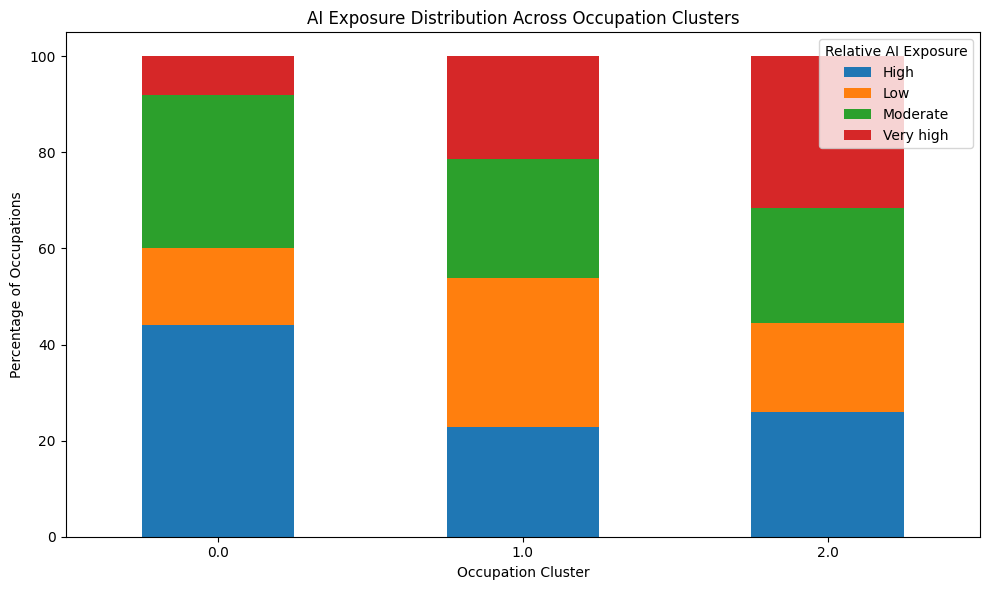

In [54]:
# Create stacked bar chart
exposure_percentages.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("AI Exposure Distribution Across Occupation Clusters")
plt.xlabel("Occupation Cluster")
plt.ylabel("Percentage of Occupations")
plt.legend(title="Relative AI Exposure")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../visualizations/ai_exposure_by_cluster.png",
            dpi=300, bbox_inches="tight")

plt.show()


In [55]:
#Validate the clusters
# Calculate silhouette score for final model
final_silhouette = silhouette_score(
    scaled_data,
    cluster_labels
)

print("Final Silhouette Score:", final_silhouette)

Final Silhouette Score: 0.30702041270448605


In [56]:
#Examine occupations in each cluster
for cluster in range(3):

    print("\nCluster", cluster)

    occupations = df[df["Cluster"] == cluster][
        [
            "2025 National Employment Matrix title",
            "Median annual wage, dollars, 2025",
            "Relative AI exposure"
        ]
    ]

    print(occupations.head(5).to_string(index=False))


Cluster 0
  2025 National Employment Matrix title  Median annual wage, dollars, 2025 Relative AI exposure
                       Chief executives                           213990.0            Very high
Industrial-organizational psychologists                           193950.0            Very high
        Oral and maxillofacial surgeons                           352220.0                  Low
                          Orthodontists                           289140.0             Moderate
                        Prosthodontists                           311180.0                  Low

Cluster 1
                        2025 National Employment Matrix title  Median annual wage, dollars, 2025 Relative AI exposure
                          Advertising and promotions managers                           133660.0            Very high
                                         Fundraising managers                           125470.0                 High
                           Compensation and bene

In [57]:
# Reduce the five clustering features to two dimensions
pca = PCA(n_components=2)

pca_data = pca.fit_transform(scaled_data)

## Create a DataFrame with the PCA results
pca_df = pd.DataFrame(
    pca_data,
    columns=["PC1", "PC2"]
)

# Add the existing K-means cluster labels
pca_df["Cluster"] = cluster_labels

print(pca_df.head())

        PC1       PC2  Cluster
0  0.486286  1.872904        0
1  3.775771  0.556870        2
2 -1.340110  0.191935        1
3  1.464321  1.620073        2
4  2.040768  1.203956        2


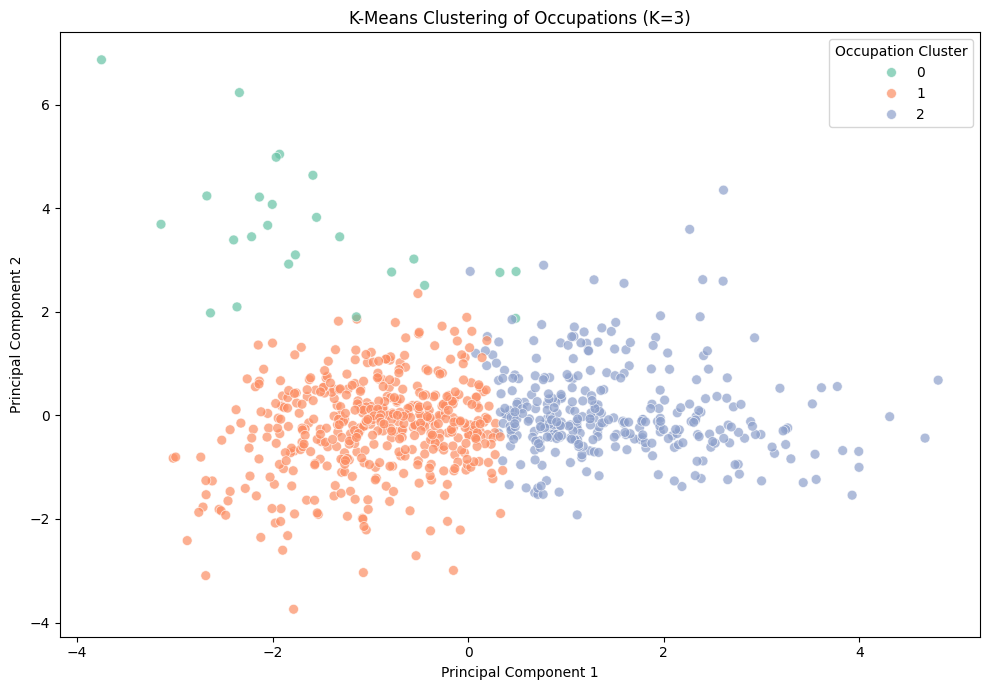

In [58]:
#Main visualization
# Create the scatter plot
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set2",
    s=50,
    alpha=0.7
)

plt.title("K-Means Clustering of Occupations (K=3)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Occupation Cluster")
plt.tight_layout()
plt.savefig("../visualizations/kmeans_pca_clusters.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [59]:
# Calculate explained variance
explained_variance = pca.explained_variance_ratio_

print("PC1:", round(explained_variance[0] * 100, 2), "%")
print("PC2:", round(explained_variance[1] * 100, 2), "%")

print(
    "Total explained variance:",
    round(sum(explained_variance) * 100, 2),
    "%"
)

PC1: 42.35 %
PC2: 24.26 %
Total explained variance: 66.61 %
